# Izhikevich neuron runner

In [1]:

import numpy as np
import torch
from pymonntorch import *
from matplotlib import pyplot as plt
from network import TimeResolution
from neuron import Izhikevich
from current import ScheduledCurrent
from parameters import PATTERNS, DT


In [ ]:
def run_pattern(p, dt=DT):
    
    net = Network(behavior={1: TimeResolution(dt=dt)})
    ng = NeuronGroup(
        net=net, size=1,
        behavior={
            10: ScheduledCurrent(schedule=p["schedule"]),
            20: Izhikevich(a=p["a"], b=p["b"], c=p["c"], d=p["d"], v_init=p["v_init"]),
            600:Recorder(["v", "u", "I"]),
            601: EventRecorder(["spikes"]),
        },
        tag="ng",
    )
    net.initialize()
    net.simulate_iterations(int(p["T"] / dt))

    v_raw = torch.as_tensor(ng["v", 0])
    v =v_raw[:, 0].cpu().numpy()
    u= torch.as_tensor(ng["u", 0])[:, 0].cpu().numpy()
    I =torch.as_tensor(ng["I", 0])[:, 0].cpu().numpy()
    t =np.arange(len(v)) * dt
    return t, v, u, I

THRESHOLD = 30  

def plot_pattern(name, p, clip=True):
    t, v, u, I = run_pattern(p)
    if clip:
        v = np.minimum(v, THRESHOLD)
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(7, 6), sharex=True,
                                        gridspec_kw={"height_ratios": [3, 2, 1]})
    ax1.plot(t, v, "k", lw=0.8)
    ax1.axhline(THRESHOLD, color="gray", ls="--", lw=0.8, label=f"spike cutoff ({THRESHOLD} mV)")
    ax1.axhline(p["c"], color="orange", ls=":", lw=0.8, label=f"reset c ({p['c']} mV)")
    ax1.legend(fontsize=7, loc="upper right")
    ax1.set_ylabel("v (mV)")
    ax1.set_title(f"{name}: {p['name']}\na={p['a']}, b={p['b']}, c={p['c']}, d={p['d']}")
   
    ax2.plot(t, u, "r", lw=0.8)
    ax2.set_ylabel("u (recovery)")
   
    ax3.plot(t, I, "b")
    ax3.set_ylabel("I"); ax3.set_xlabel("time (ms)")
   
    fig.tight_layout()
    plt.show()
    return t, v, u, I

Network['Network_1', 'Network'](Neurons: tensor(1)|1 groups, Synapses: tensor(0.)|0 groups){1:TimeResolution(dt=0.1,)}
NeuronGroup['ng', 'NeuronGroup'](1){10:ScheduledCurrent(schedule=[(0, 0), (10, 0.2), (97, 1), (102, 0.2)],)20:Izhikevich(a=0.1,b=0.26,c=-65,d=2,v_init=-62.5,)600:Recorder(variables=None,gap_width=0,max_length=None,auto_annotate=True,tag=None,arg_0=['v', 'u', 'I'],)601:EventRecorder(variables=None,gap_width=0,max_length=None,auto_annotate=True,tag=None,arg_0=['spikes'],)}
2000xBatch: 1/1 (100%) 596.066ms
Network['Network_1', 'Network'](Neurons: tensor(1)|1 groups, Synapses: tensor(0.)|0 groups){1:TimeResolution(dt=0.1,)}
NeuronGroup['ng', 'NeuronGroup'](1){10:ScheduledCurrent(schedule=[(0, 0), (10, 0.2), (97, 1), (102, 0.2)],)20:Izhikevich(a=0.1,b=0.26,c=-65,d=2,v_init=-62.5,)600:Recorder(variables=None,gap_width=0,max_length=None,auto_annotate=True,tag=None,arg_0=['v', 'u', 'I'],)601:EventRecorder(variables=None,gap_width=0,max_length=None,auto_annotate=True,tag=None,a

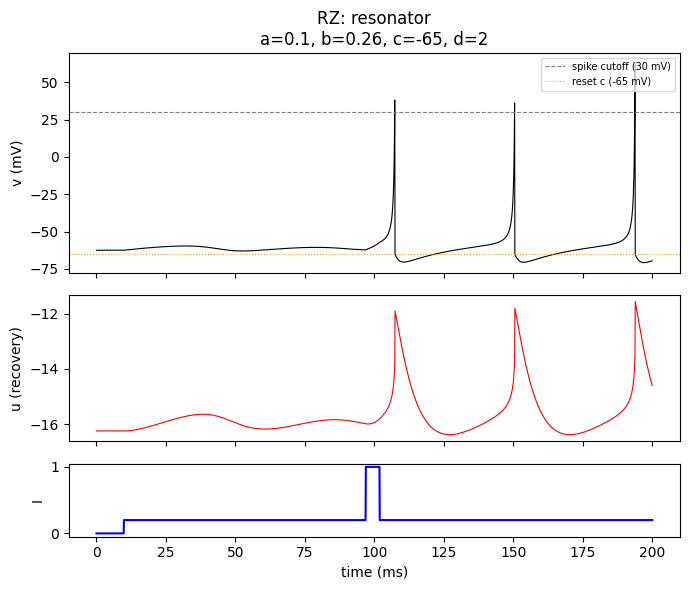

In [3]:

run_pattern(PATTERNS["RZ"])
_ = plot_pattern("RZ", PATTERNS["RZ"])

Network['Network_1', 'Network'](Neurons: tensor(1)|1 groups, Synapses: tensor(0.)|0 groups){1:TimeResolution(dt=0.1,)}
NeuronGroup['ng', 'NeuronGroup'](1){10:ScheduledCurrent(schedule=[(0, 0), (20, 10)],)20:Izhikevich(a=0.025,b=0.2,c=-65,d=8,v_init=-65,)600:Recorder(variables=None,gap_width=0,max_length=None,auto_annotate=True,tag=None,arg_0=['v', 'u', 'I'],)601:EventRecorder(variables=None,gap_width=0,max_length=None,auto_annotate=True,tag=None,arg_0=['spikes'],)}
2000xBatch: 1/1 (100%) 1690.923ms


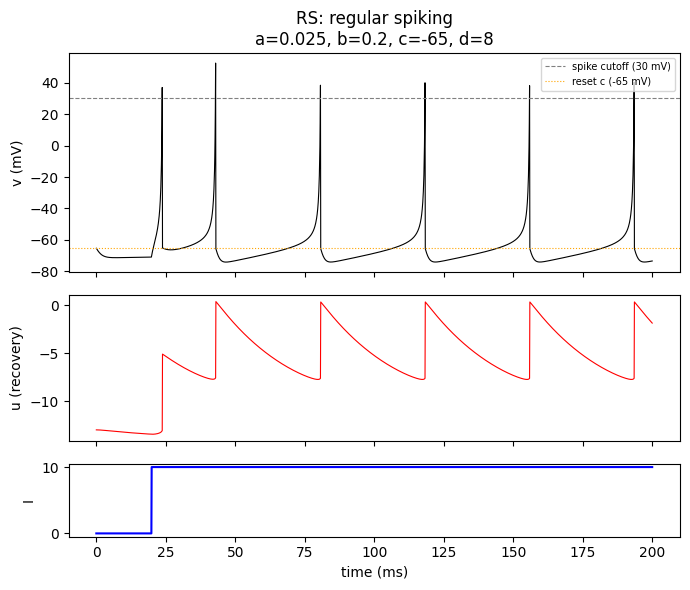

Network['Network_1', 'Network'](Neurons: tensor(1)|1 groups, Synapses: tensor(0.)|0 groups){1:TimeResolution(dt=0.1,)}
NeuronGroup['ng', 'NeuronGroup'](1){10:ScheduledCurrent(schedule=[(0, 0), (20, 10)],)20:Izhikevich(a=0.0225,b=0.2,c=-55,d=4,v_init=-65,)600:Recorder(variables=None,gap_width=0,max_length=None,auto_annotate=True,tag=None,arg_0=['v', 'u', 'I'],)601:EventRecorder(variables=None,gap_width=0,max_length=None,auto_annotate=True,tag=None,arg_0=['spikes'],)}
2000xBatch: 1/1 (100%) 1918.452ms


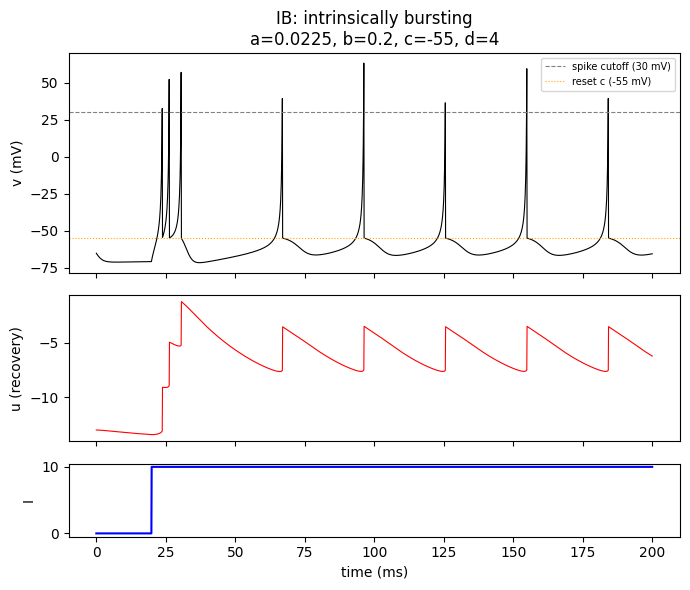

Network['Network_1', 'Network'](Neurons: tensor(1)|1 groups, Synapses: tensor(0.)|0 groups){1:TimeResolution(dt=0.1,)}
NeuronGroup['ng', 'NeuronGroup'](1){10:ScheduledCurrent(schedule=[(0, 0), (20, 10)],)20:Izhikevich(a=0.02,b=0.2,c=-50,d=2,v_init=-65,)600:Recorder(variables=None,gap_width=0,max_length=None,auto_annotate=True,tag=None,arg_0=['v', 'u', 'I'],)601:EventRecorder(variables=None,gap_width=0,max_length=None,auto_annotate=True,tag=None,arg_0=['spikes'],)}
2000xBatch: 1/1 (100%) 1590.265ms


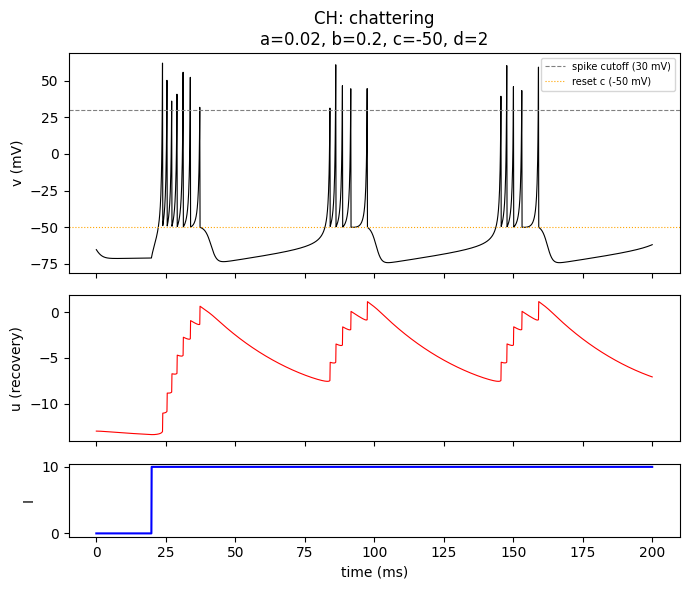

Network['Network_1', 'Network'](Neurons: tensor(1)|1 groups, Synapses: tensor(0.)|0 groups){1:TimeResolution(dt=0.1,)}
NeuronGroup['ng', 'NeuronGroup'](1){10:ScheduledCurrent(schedule=[(0, 0), (20, 10)],)20:Izhikevich(a=0.1,b=0.2,c=-65,d=2,v_init=-65,)600:Recorder(variables=None,gap_width=0,max_length=None,auto_annotate=True,tag=None,arg_0=['v', 'u', 'I'],)601:EventRecorder(variables=None,gap_width=0,max_length=None,auto_annotate=True,tag=None,arg_0=['spikes'],)}
2000xBatch: 1/1 (100%) 1770.007ms


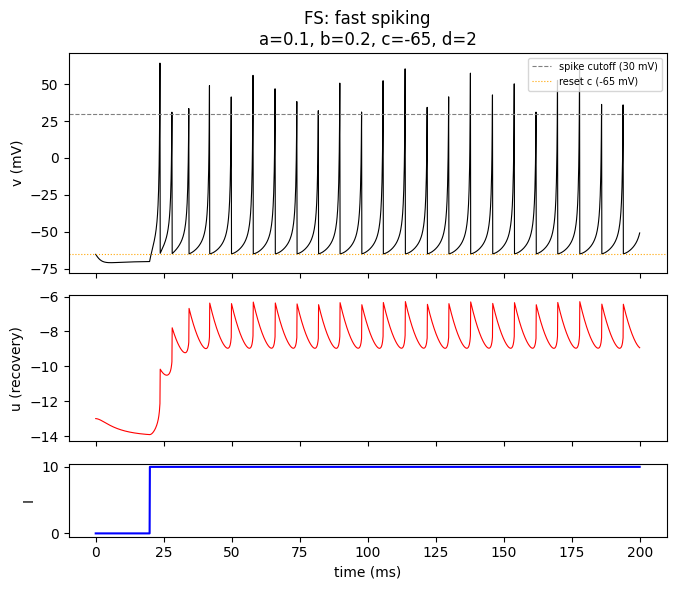

Network['Network_1', 'Network'](Neurons: tensor(1)|1 groups, Synapses: tensor(0.)|0 groups){1:TimeResolution(dt=0.1,)}
NeuronGroup['ng', 'NeuronGroup'](1){10:ScheduledCurrent(schedule=[(0, 0), (20, 10)],)20:Izhikevich(a=0.02,b=0.25,c=-65,d=2,v_init=-65,)600:Recorder(variables=None,gap_width=0,max_length=None,auto_annotate=True,tag=None,arg_0=['v', 'u', 'I'],)601:EventRecorder(variables=None,gap_width=0,max_length=None,auto_annotate=True,tag=None,arg_0=['spikes'],)}
2000xBatch: 1/1 (100%) 1340.404ms


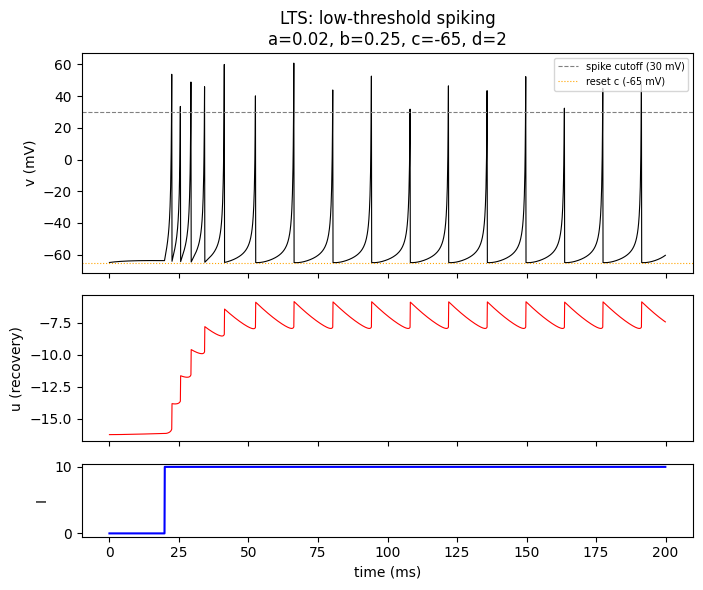

Network['Network_1', 'Network'](Neurons: tensor(1)|1 groups, Synapses: tensor(0.)|0 groups){1:TimeResolution(dt=0.1,)}
NeuronGroup['ng', 'NeuronGroup'](1){10:ScheduledCurrent(schedule=[(0, 0), (20, 10)],)20:Izhikevich(a=0.02,b=0.25,c=-65,d=0.05,v_init=-63,)600:Recorder(variables=None,gap_width=0,max_length=None,auto_annotate=True,tag=None,arg_0=['v', 'u', 'I'],)601:EventRecorder(variables=None,gap_width=0,max_length=None,auto_annotate=True,tag=None,arg_0=['spikes'],)}
2000xBatch: 1/1 (100%) 1331.820ms


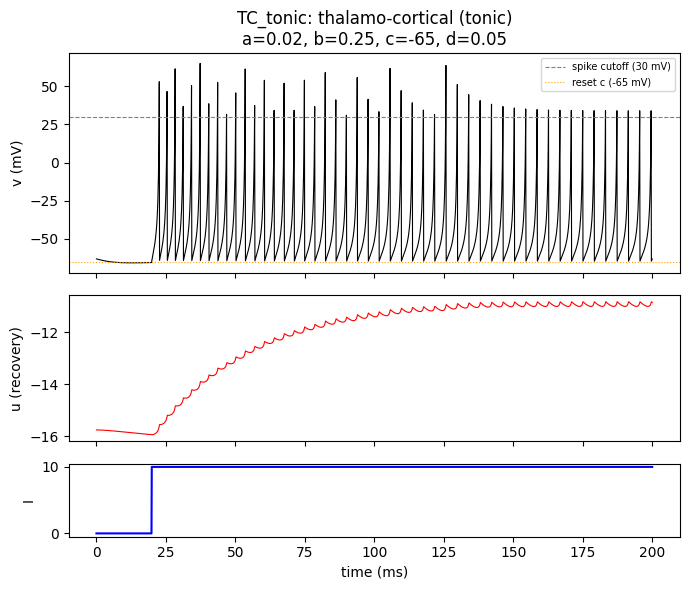

Network['Network_1', 'Network'](Neurons: tensor(1)|1 groups, Synapses: tensor(0.)|0 groups){1:TimeResolution(dt=0.1,)}
NeuronGroup['ng', 'NeuronGroup'](1){10:ScheduledCurrent(schedule=[(0, -10), (200, 0)],)20:Izhikevich(a=0.02,b=0.25,c=-65,d=0.05,v_init=-87,)600:Recorder(variables=None,gap_width=0,max_length=None,auto_annotate=True,tag=None,arg_0=['v', 'u', 'I'],)601:EventRecorder(variables=None,gap_width=0,max_length=None,auto_annotate=True,tag=None,arg_0=['spikes'],)}
3000xBatch: 1/1 (100%) 2027.923ms


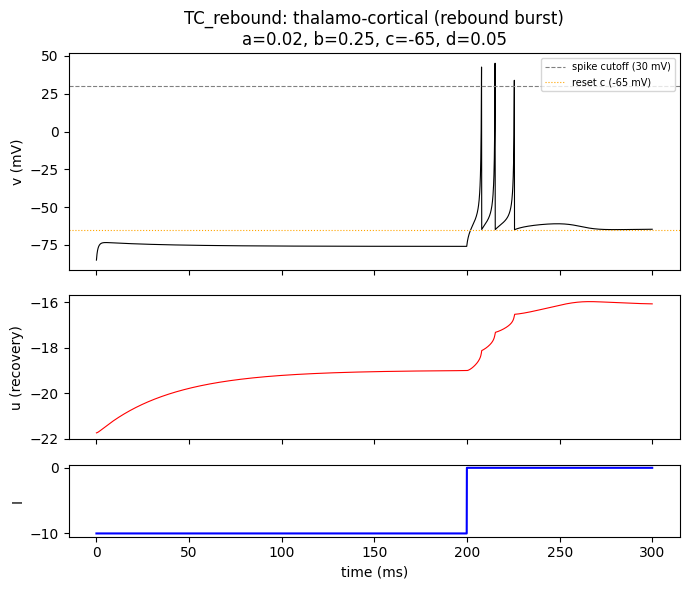

Network['Network_1', 'Network'](Neurons: tensor(1)|1 groups, Synapses: tensor(0.)|0 groups){1:TimeResolution(dt=0.1,)}
NeuronGroup['ng', 'NeuronGroup'](1){10:ScheduledCurrent(schedule=[(0, 0), (10, 0.2), (97, 1), (102, 0.2)],)20:Izhikevich(a=0.1,b=0.26,c=-65,d=2,v_init=-62.5,)600:Recorder(variables=None,gap_width=0,max_length=None,auto_annotate=True,tag=None,arg_0=['v', 'u', 'I'],)601:EventRecorder(variables=None,gap_width=0,max_length=None,auto_annotate=True,tag=None,arg_0=['spikes'],)}
2000xBatch: 1/1 (100%) 1683.964ms


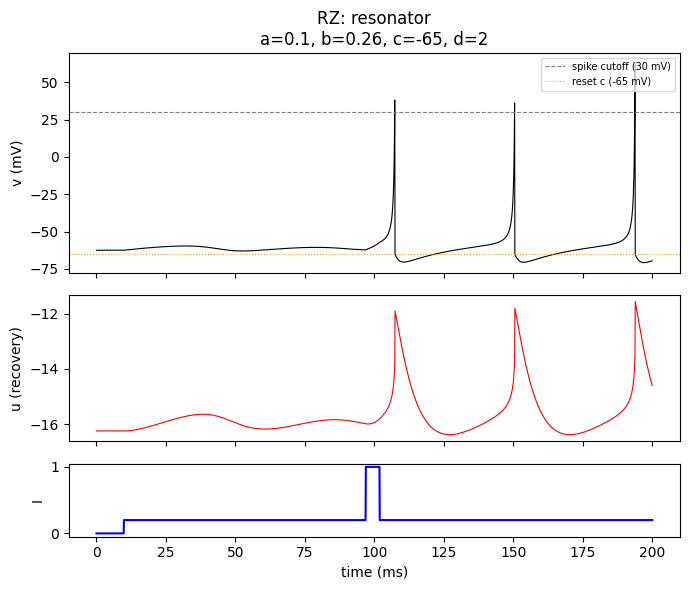

In [4]:
for name, p in PATTERNS.items():
    plot_pattern(name, p)
    

## Parameter table

In [5]:
print("| Pattern | a | b | c | d | v_init | I schedule |")
print("|---|---|---|---|---|---|---|")
for name, p in PATTERNS.items():
    print(f"| {name} ({p['name']}) | {p['a']} | {p['b']} | {p['c']} | {p['d']} | {p['v_init']} | {p['schedule']} |")

| Pattern | a | b | c | d | v_init | I schedule |
|---|---|---|---|---|---|---|
| RS (regular spiking) | 0.025 | 0.2 | -65 | 8 | -65 | [(0, 0), (20, 10)] |
| IB (intrinsically bursting) | 0.0225 | 0.2 | -55 | 4 | -65 | [(0, 0), (20, 10)] |
| CH (chattering) | 0.02 | 0.2 | -50 | 2 | -65 | [(0, 0), (20, 10)] |
| FS (fast spiking) | 0.1 | 0.2 | -65 | 2 | -65 | [(0, 0), (20, 10)] |
| LTS (low-threshold spiking) | 0.02 | 0.25 | -65 | 2 | -65 | [(0, 0), (20, 10)] |
| TC_tonic (thalamo-cortical (tonic)) | 0.02 | 0.25 | -65 | 0.05 | -63 | [(0, 0), (20, 10)] |
| TC_rebound (thalamo-cortical (rebound burst)) | 0.02 | 0.25 | -65 | 0.05 | -87 | [(0, -10), (200, 0)] |
| RZ (resonator) | 0.1 | 0.26 | -65 | 2 | -62.5 | [(0, 0), (10, 0.2), (97, 1), (102, 0.2)] |
